# Urban Green Cover and Population Growth
**Problem Statement:** Examine how urban green-space indicates changes alongside population growth and urban expansion

### Data Sources
- **Green Cover:** City NDVI(a satellite greenness index,higher = greener) fro 2010, 2015, 2020, 2021 from the city greenspace dataset.
- **Population and Density:** UN DESA *World Urbanization Prospects 2025*(Files 21 and 34).
- **Land Area:** calculated by me as population/density(the UN land-ares files was not used).

In [2]:
import os 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

os.makedirs("charts", exist_ok=True)
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

C:\Users\princ\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\princ\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 1: Collect population, land-use and green-space indicators for comparable places and time periods.
I have loaded the 4 sheet of the prepared dataset and what is inside

In [3]:
file_name = "Urban_Green_Cover_Final_Dataset.xlsx"
wide = pd.read_excel(file_name, sheet_name="City_Summary_Wide")
long = pd.read_excel(file_name, sheet_name="City_Year_Long")
unmatched = pd.read_excel(file_name, sheet_name="Unmatched_Cities")
dictionary = pd.read_excel(file_name, sheet_name="Data_Dictionary")

print("Wide table shape:", wide.shape[0])
print("Long table shape:", long.shape[0])
print("Unmatched cities shape:", unmatched.shape[0])
print("Dictionary shape:", dictionary.shape[0])

Wide table shape: 1038
Long table shape: 4152
Unmatched cities shape: 85
Dictionary shape: 14


In [4]:
wide.head(3)

,City,Country,Major_Geo_Region,HDI_level,Climate_region,WHO_region,ISO3_Code,City_Code,WUP_City_Name,Match_Type,...,WUP_Land_Area_km2_2020,WUP_Land_Area_km2_2021,NDVI_change_2010_2020,Pop_growth_pct_2010_2020,Area_growth_pct_2010_2020,NDVI_change_2015_2020,Pop_growth_pct_2015_2020,Area_growth_pct_2015_2020,Longitude,Latitude
0,Aba,Nigeria,Africa,Low,Tropical,Africa,NGA,7785.0,Aba,exact_name,...,184.999881,185.799877,0.059070,32.284117,28.472145,-0.076121,11.673534,3.351872,7.352215,5.102898
1,Abbottabad,Pakistan,Asia,Medium,Temperate,Eastern Mediterranean,PAK,7045.0,Abbottabad,exact_name,...,107.000052,107.800064,0.050275,9.421621,13.829890,-0.005598,0.660094,4.902022,73.228832,34.177822
2,Abeokuta,Nigeria,Africa,Low,Tropical,Africa,NGA,1570.0,Abeokuta,exact_name,...,169.000039,170.799917,0.082825,16.551963,8.333269,-0.009434,7.653565,3.681046,3.342968,7.161728


In [5]:
long.head(3)

,City,Country,Major_Geo_Region,HDI_level,Climate_region,WHO_region,ISO3_Code,City_Code,WUP_City_Name,Match_Type,Year,NDVI_annual_avg,NDVI_peak,NDVI_annual_pop_weighted,Greenness_Level,WUP_Population_thousands,WUP_Land_Area_km2,WUP_Density_per_km2,Longitude,Latitude
0,Herat,Afghanistan,Asia,Low,Arid,Eastern Mediterranean,AFG,742.0,Herat,exact_name,2010,0.164070,0.220683,0.187444,Very Low,668.974,70.999993,9422.17,62.205237,34.349858
1,Herat,Afghanistan,Asia,Low,Arid,Eastern Mediterranean,AFG,742.0,Herat,exact_name,2015,0.176511,0.239405,0.196993,Very Low,878.077,75.000021,11707.69,62.205237,34.349858
2,Herat,Afghanistan,Asia,Low,Arid,Eastern Mediterranean,AFG,742.0,Herat,exact_name,2020,0.164452,0.205323,0.183483,Very Low,1181.815,81.999989,14412.38,62.205237,34.349858


In [6]:
wide.dtypes

City                                 str
Country                              str
Major_Geo_Region                     str
HDI_level                            str
Climate_region                       str
WHO_region                           str
ISO3_Code                            str
City_Code                        float64
WUP_City_Name                        str
Match_Type                           str
NDVI_annual_avg_2010             float64
NDVI_annual_avg_2015             float64
NDVI_annual_avg_2020             float64
NDVI_annual_avg_2021             float64
WUP_Population_thousands_2010    float64
WUP_Population_thousands_2015    float64
WUP_Population_thousands_2020    float64
WUP_Population_thousands_2021    float64
WUP_Land_Area_km2_2010           float64
WUP_Land_Area_km2_2015           float64
WUP_Land_Area_km2_2020           float64
WUP_Land_Area_km2_2021           float64
NDVI_change_2010_2020            float64
Pop_growth_pct_2010_2020         float64
Area_growth_pct_

In [7]:
indicators =pd.DataFrame({
    "Indicator":["Green cover(NDVI)", "Population", "Population density","Land area"],
    "Unit":["index(0 to 1,higher = greener)", "thousands of people", "people per sq.km", "sq.km"],
    "Source":["City greenspace dataset (satellite)","UN World Urbanization Prospects 2025 (File 21)","UN World Urbanization Prospects 2025 (File 34)","Derived population / density"],
    "Years":["2010,2015,2020,2021"] * 4
})
indicators

,Indicator,Unit,Source,Years
0,Green cover(NDVI),"index(0 to 1,higher = greener)",City greenspace dataset (satellite),"2010,2015,2020,2021"
1,Population,thousands of people,UN World Urbanization Prospects 2025 (File 21),"2010,2015,2020,2021"
2,Population density,people per sq.km,UN World Urbanization Prospects 2025 (File 34),"2010,2015,2020,2021"
3,Land area,sq.km,Derived population / density,"2010,2015,2020,2021"


**Question 1 summary:** the data has green cover (NDVI),population and land -use information (land  area and density) for 1038 cities in 172 countries, for the same 4 year (2010,2015, 2020, 2021) Land use is represented by the city's land area and population density;there is no separate land -cover classification.

## 2. Align geographical boundaries, years, units and location labels
We check that all cities share the same years,units and labels, then keep only the cities that were successfully match to a un city (these have the population data)

In [8]:
print("Years in the long table:", sorted(long['Year'].unique()))
print("Rows per Year:")
print(long["Year"].value_counts().sort_index())

Years in the long table: [np.int64(2010), np.int64(2015), np.int64(2020), np.int64(2021)]
Rows per Year:
Year
2010    1038
2015    1038
2020    1038
2021    1038
Name: count, dtype: int64


In [9]:
wide["City"]= wide["City"].str.strip()
wide["Country"]= wide["Country"].str.strip()
long["City"]= long["City"].str.strip()
long["Country"]= long["Country"].str.strip()
print("Duplicate city + country pairs in the wide table :",wide .duplicated(["City","Country"]).sum())
print("Number of  countries :",wide["Country"].nunique())

Duplicate city + country pairs in the wide table : 0
Number of  countries : 172


In [10]:
print("units are consistent: NDVI = index, population =thousands,area=sq.km,")
wide["Match_Type"].value_counts()

units are consistent: NDVI = index, population =thousands,area=sq.km,


Match_Type
exact_name                       900
unmatched                         85
name_ambiguous_largest_chosen     47
manual_alias                       6
Name: count, dtype: int64

In [11]:
matched=wide[wide["Match_Type"]!="unmatched"].copy()
match_long=long[long["Match_Type"]!="unmatched"].copy()
print("city in the full dataset:",len(wide))
print("city in the matched dataset:",len(matched))
print("Cities left out of the matched dataset:",len(wide)-len(matched))


city in the full dataset: 1038
city in the matched dataset: 953
Cities left out of the matched dataset: 85


In [12]:
needed =["NDVI_change_2015_2020", "Pop_growth_pct_2015_2020","Area_growth_pct_2015_2020"]
analysis=matched.dropna(subset=needed).copy()
keys=analysis[["City","Country"]]
analysis_long = match_long.merge(keys, on=["City", "Country"])
print("Cities in the analysis dataset:",len(analysis))
print()
print("Cities per region:")
print(analysis["Major_Geo_Region"].value_counts())


Cities in the analysis dataset: 948

Cities per region:
Major_Geo_Region
Asia                               507
Africa                             142
Europe                             123
Latin America and the Caribbean    116
Northern America                    51
Oceania                              9
Name: count, dtype: int64


**Task 2 summary:** all cities use the same four years and the same units. We keep the matched cities that also have complete 2015 to 2020 growth numbers; this is the group called `analysis` in the rest of the notebook.

## Task 3: Investigate missing or incompatible records and document assumptions

In [13]:
# Missing values in the wide table: count and percent per column
missing = pd.DataFrame({
    "Missing_count": wide.isna().sum(),
    "Missing_percent": (wide.isna().mean() * 100).round(1)
})
missing[missing["Missing_count"] > 0]

,Missing_count,Missing_percent
ISO3_Code,85,8.2
City_Code,85,8.2
WUP_City_Name,85,8.2
NDVI_annual_avg_2010,2,0.2
NDVI_annual_avg_2021,1,0.1
WUP_Population_thousands_2010,90,8.7
WUP_Population_thousands_2015,89,8.6
WUP_Population_thousands_2020,90,8.7
WUP_Population_thousands_2021,90,8.7
WUP_Land_Area_km2_2010,90,8.7


In [14]:
# Which cities could not be matched to the UN data, by country?
unmatched_cities = wide[wide["Match_Type"] == "unmatched"]
print("Unmatched cities:", len(unmatched_cities))
print()
print(unmatched_cities["Country"].value_counts().head(10))

Unmatched cities: 85

Country
China                               22
India                               13
United States of America             7
Bangladesh                           6
Egypt                                4
Indonesia                            4
Nigeria                              3
Iraq                                 3
Democratic Republic of the Congo     3
Brazil                               2
Name: count, dtype: int64


In [15]:
# Cities whose name appears more than once in the UN data (we picked the largest one)
ambiguous = wide[wide["Match_Type"] == "name_ambiguous_largest_chosen"]
print("Ambiguous city names:", len(ambiguous))
ambiguous[["City", "Country", "WUP_City_Name"]].head(15)

Ambiguous city names: 47


,City,Country,WUP_City_Name
34,Al-Minya,Egypt,Al Minya
85,Banda,India,Banda
132,Bilaspur,India,Bilaspur
134,Binhai,China,Binhai
179,Campo Grande,Brazil,Campo Grande
255,Datong,China,Datong
309,Fatehpur,India,Fatehpur
320,Fushun,China,Fushun
322,Fuyang,China,Fuyang
349,Guiyang,China,Guiyang


In [16]:
# Check the NDVI jump between 2010 and 2015 (possible incompatibility between years)
print("Average NDVI 2010:", round(matched["NDVI_annual_avg_2010"].mean(), 3))
print("Average NDVI 2015:", round(matched["NDVI_annual_avg_2015"].mean(), 3))

# Share of cities where NDVI is higher in 2015 than in 2010
share_up = (matched["NDVI_annual_avg_2015"] > matched["NDVI_annual_avg_2010"]).mean() * 100
print("Cities with higher NDVI in 2015 than in 2010:", round(share_up, 1), "%")

Average NDVI 2010: 0.234
Average NDVI 2015: 0.283
Cities with higher NDVI in 2015 than in 2010: 90.8 %


### Assumptions and decisions
1. **Land area is derived.** We calculated land area as population divided by density because the UN land-area file was not used.
2. **City boundaries differ between sources.** The NDVI cities and the UN cities are defined differently, so some differences are expected.
3. **Ambiguous city names.** When several UN cities share a name in the same country, we used the largest one.
4. **Unmatched cities are excluded** from all population and area analysis because they have no UN data.
5. **2010 is treated with caution.** NDVI jumps for most cities between 2010 and 2015, which is probably a change of satellite or method and not real greening. All change analysis uses **2015 to 2020**.
6. **A few matched cities have missing population values** in the UN data; they are dropped from the growth analysis only.
7. **Population is a city-level average.** It does not show differences inside a city.

## Task 4: Compare green-cover indicators and population trends over time

In [17]:
# (a) Average NDVI and population for each year (same cities in every year)
by_year = analysis_long.groupby("Year").agg(
    Average_NDVI=("NDVI_annual_avg", "mean"),
    Average_population_thousands=("WUP_Population_thousands", "mean"),
    Total_population_thousands=("WUP_Population_thousands", "sum"),
    Cities=("City", "count")
).round(3)
by_year

,Average_NDVI,Average_population_thousands,Total_population_thousands,Cities
Year,,,,
2010,0.234,1685.638,1596298.891,948
2015,0.282,1835.644,1740190.340,948
2020,0.285,1990.292,1886796.521,948
2021,0.279,2007.285,1902906.301,948


In [18]:
# (b) Share of cities that got greener or less green between 2015 and 2020
greener = (analysis["NDVI_change_2015_2020"] > 0).mean() * 100
browner = (analysis["NDVI_change_2015_2020"] < 0).mean() * 100
print("Cities with higher NDVI in 2020 than 2015:", round(greener, 1), "%")
print("Cities with lower NDVI in 2020 than 2015:", round(browner, 1), "%")

Cities with higher NDVI in 2020 than 2015: 51.3 %
Cities with lower NDVI in 2020 than 2015: 48.7 %


In [19]:
# (c) Summary statistics of change between 2015 and 2020
analysis[["Pop_growth_pct_2015_2020", "Area_growth_pct_2015_2020", "NDVI_change_2015_2020"]].describe().round(3)

,Pop_growth_pct_2015_2020,Area_growth_pct_2015_2020,NDVI_change_2015_2020
count,948.000,948.000,948.000
mean,6.722,5.202,0.002
std,13.123,9.761,0.030
min,-51.476,-36.364,-0.114
25%,0.537,0.000,-0.014
50%,5.205,2.556,0.001
75%,11.553,7.523,0.018
max,118.114,67.568,0.117


In [20]:
# (d) Spearman correlation: is NDVI change linked to population growth or area growth?
corr_pop, p_pop = spearmanr(analysis["NDVI_change_2015_2020"], analysis["Pop_growth_pct_2015_2020"])
corr_area, p_area = spearmanr(analysis["NDVI_change_2015_2020"], analysis["Area_growth_pct_2015_2020"])

print("NDVI change vs population growth: rho =", round(corr_pop, 3), ", p-value =", round(p_pop, 3))
print("NDVI change vs area growth:       rho =", round(corr_area, 3), ", p-value =", round(p_area, 3))
print()

# Plain-English reading (0.05 is the usual cut-off)
if p_pop < 0.05:
    print("Population growth: a statistically significant relationship was found.")
else:
    print("Population growth: no statistically significant relationship at the 5% level.")
if p_area < 0.05:
    print("Area growth: a statistically significant relationship was found.")
else:
    print("Area growth: no statistically significant relationship at the 5% level.")

NDVI change vs population growth: rho = -0.057 , p-value = 0.081
NDVI change vs area growth:       rho = 0.019 , p-value = 0.559

Population growth: no statistically significant relationship at the 5% level.
Area growth: no statistically significant relationship at the 5% level.


In [21]:
# (e) Split cities into 4 equal groups by population growth and compare the average NDVI change
analysis["Growth_group"] = pd.qcut(
    analysis["Pop_growth_pct_2015_2020"], 4,
    labels=["1 Lowest growth", "2", "3", "4 Highest growth"]
)
group_table = analysis.groupby("Growth_group", observed=True).agg(
    Cities=("City", "count"),
    Average_pop_growth_pct=("Pop_growth_pct_2015_2020", "mean"),
    Average_NDVI_change=("NDVI_change_2015_2020", "mean")
).round(4)
group_table

,Cities,Average_pop_growth_pct,Average_NDVI_change
Growth_group,,,
1 Lowest growth,237,-6.4209,0.0042
2,237,2.9241,0.0049
3,237,8.0303,0.0019
4 Highest growth,237,22.3548,-0.0018


**Task 4 summary:** average NDVI is about 0.28 in 2015, 2020 and 2021, while average city population keeps rising. About half of the cities became slightly greener between 2015 and 2020 and about half became slightly less green. The Spearman correlation between NDVI change and population growth is very weak (about -0.06, not significant at the 5% level) and the correlation with area growth is close to zero (about 0.02). The fastest-growing group of cities has a slightly negative average NDVI change, but the size of the difference is very small.

## Task 5: Trend charts, regional comparisons and maps

### Chart 1: Average NDVI over time

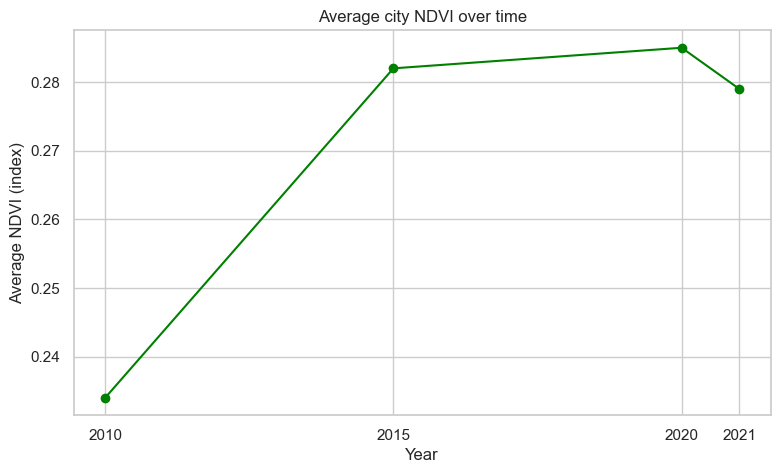

In [22]:
plt.figure()
plt.plot(by_year.index, by_year["Average_NDVI"], marker="o", color="green")
plt.title("Average city NDVI over time")
plt.xlabel("Year")
plt.ylabel("Average NDVI (index)")
plt.xticks([2010, 2015, 2020, 2021])
plt.savefig("charts/1_ndvi_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** average NDVI rises sharply from about 0.23 in 2010 to about 0.28 in 2015, then stays almost flat in 2015, 2020 and 2021. The 2010 jump is too uniform across cities to be real greening, so it is probably a data or satellite-method effect (see Task 3). We therefore rely on 2015 to 2020.

### Chart 2: Average city population over time

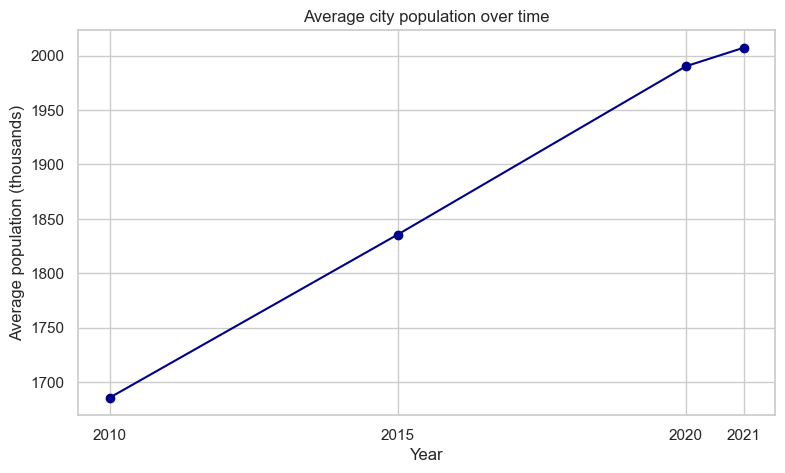

In [23]:
plt.figure()
plt.plot(by_year.index, by_year["Average_population_thousands"], marker="o", color="darkblue")
plt.title("Average city population over time")
plt.xlabel("Year")
plt.ylabel("Average population (thousands)")
plt.xticks([2010, 2015, 2020, 2021])
plt.savefig("charts/2_population_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** average city population rises steadily in every period, from roughly 1.7 million in 2010 to about 2.0 million in 2021. Cities are growing while average NDVI is flat after 2015.

### Chart 3: NDVI over time in some large cities

Cities found: <ArrowStringArray>
['São Paulo', 'Shanghai', 'Bengaluru', 'Delhi [New Delhi]', 'Mumbai', 'Lagos']
Length: 6, dtype: str


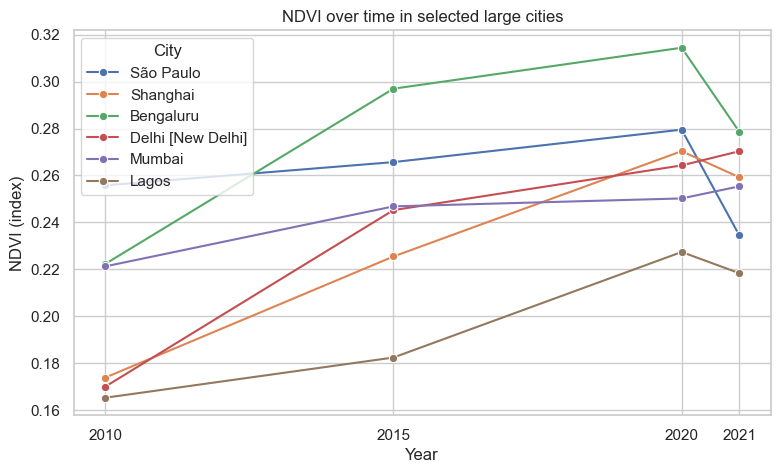

In [24]:
# Pick some well-known large cities (cities that are not in the data are skipped automatically)
big_cities = ["Mumbai", "Delhi [New Delhi]", "Bengaluru", "Shanghai", "Lagos", "São Paulo"]
big = analysis_long[analysis_long["City"].isin(big_cities)]
print("Cities found:", big["City"].unique())

plt.figure()
sns.lineplot(data=big, x="Year", y="NDVI_annual_avg", hue="City", marker="o")
plt.title("NDVI over time in selected large cities")
plt.xlabel("Year")
plt.ylabel("NDVI (index)")
plt.xticks([2010, 2015, 2020, 2021])
plt.savefig("charts/3_big_cities_ndvi.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** each line is one city. All six cities rise between 2010 and 2015 (the data issue noted earlier). Between 2015 and 2020 all six rise modestly, and in 2021 four of the six (Bengaluru, Lagos, Shanghai, Sao Paulo) drop slightly while Delhi and Mumbai edge up. Cities differ in their level of greenness more than in their change over time, and one year of change (2021) can reverse the previous gain.

### Chart 4: Population growth vs NDVI change

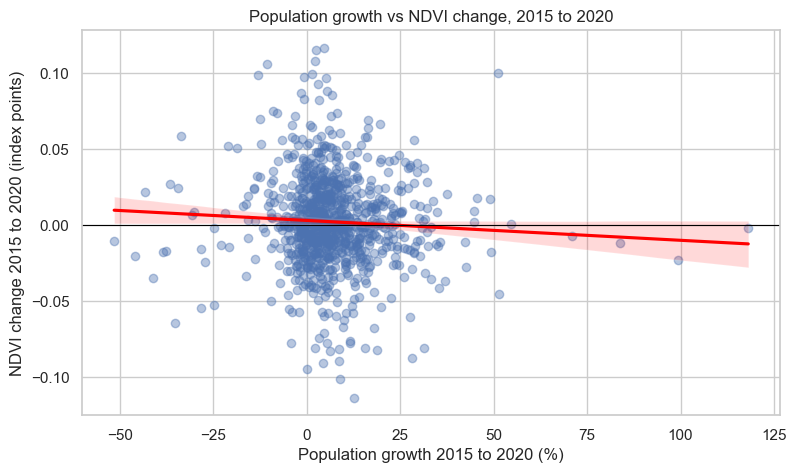

In [25]:
plt.figure()
sns.regplot(data=analysis, x="Pop_growth_pct_2015_2020", y="NDVI_change_2015_2020",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Population growth vs NDVI change, 2015 to 2020")
plt.xlabel("Population growth 2015 to 2020 (%)")
plt.ylabel("NDVI change 2015 to 2020 (index points)")
plt.savefig("charts/4_pop_growth_vs_ndvi_change.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** the points form a wide cloud around zero and the red trend line is almost flat (slightly downward). This matches the weak Spearman result from Task 4 (about -0.06, not significant). Cities with similar population growth have very different NDVI changes.

### Chart 5: Urban area growth vs NDVI change

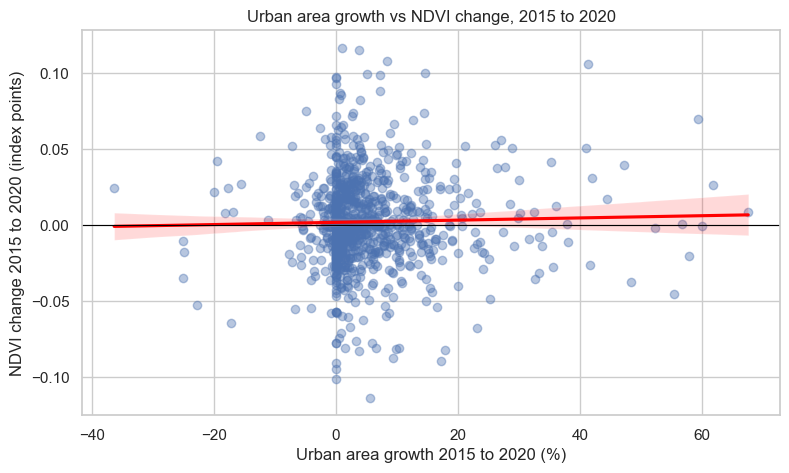

In [26]:
plt.figure()
sns.regplot(data=analysis, x="Area_growth_pct_2015_2020", y="NDVI_change_2015_2020",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Urban area growth vs NDVI change, 2015 to 2020")
plt.xlabel("Urban area growth 2015 to 2020 (%)")
plt.ylabel("NDVI change 2015 to 2020 (index points)")
plt.savefig("charts/5_area_growth_vs_ndvi_change.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** the trend line is essentially flat, matching the correlation of about 0.02. Cities that expanded more in area did not show a clear gain or loss in NDVI.

### Chart 6: Regional comparisons

                                 Cities  NDVI_2020  NDVI_change
Major_Geo_Region                                               
Africa                              142      0.258       -0.006
Asia                                507      0.282        0.007
Europe                              123      0.304        0.004
Latin America and the Caribbean     116      0.294       -0.005
Northern America                     51      0.316       -0.004
Oceania                               9      0.310       -0.015



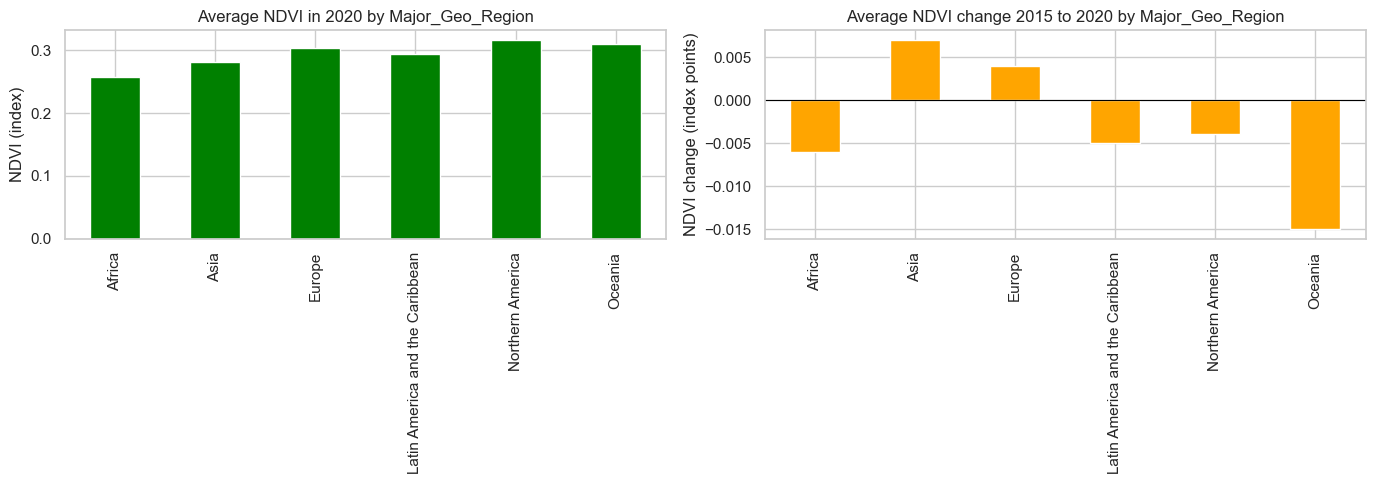

           Cities  NDVI_2020  NDVI_change
HDI_level                                
High          356      0.276        0.002
Low            87      0.245       -0.005
Medium        259      0.310        0.007
Very high     246      0.285        0.000



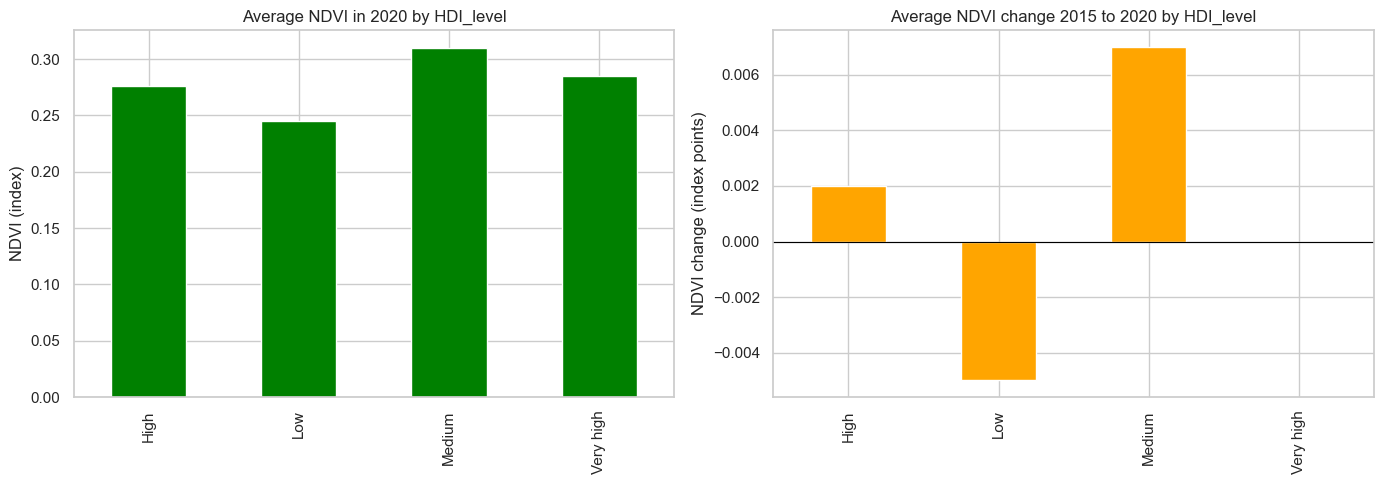

                Cities  NDVI_2020  NDVI_change
Climate_region                                
Arid               215      0.209        0.001
Continental        135      0.270        0.005
Temperate          337      0.298        0.004
Tropical           260      0.338       -0.000



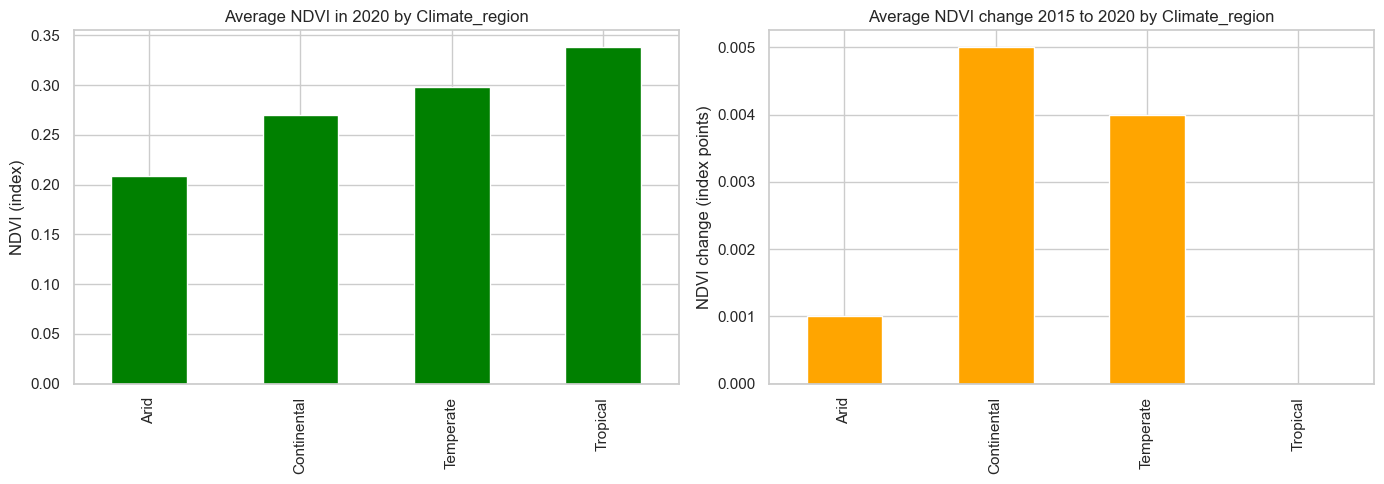

In [27]:
# Average NDVI in 2020 and average NDVI change, for three ways of grouping the cities
group_columns = ["Major_Geo_Region", "HDI_level", "Climate_region"]

for col in group_columns:
    data = analysis
    if col == "Climate_region":
        data = analysis[analysis["Climate_region"] != "Polar"]   # only 1 polar city, so we leave it out

    table = data.groupby(col).agg(
        Cities=("City", "count"),
        NDVI_2020=("NDVI_annual_avg_2020", "mean"),
        NDVI_change=("NDVI_change_2015_2020", "mean")
    ).round(3)
    print(table)
    print()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    table["NDVI_2020"].plot(kind="bar", ax=axes[0], color="green")
    axes[0].set_title("Average NDVI in 2020 by " + col)
    axes[0].set_ylabel("NDVI (index)")
    axes[0].set_xlabel("")
    table["NDVI_change"].plot(kind="bar", ax=axes[1], color="orange")
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_title("Average NDVI change 2015 to 2020 by " + col)
    axes[1].set_ylabel("NDVI change (index points)")
    axes[1].set_xlabel("")
    plt.tight_layout()
    plt.savefig("charts/6_" + col + ".png", dpi=150, bbox_inches="tight")
    plt.show()

**Interpretation:**
- **Level of greenness (2020):** Northern America (about 0.32) and Europe (about 0.30) have the highest average NDVI and Africa the lowest (about 0.26). By climate, tropical cities are greenest (about 0.34) and arid cities least green (about 0.21). By HDI group, low-HDI cities have the lowest NDVI (about 0.25).
- **Change (2015 to 2020):** differences are small (all under 0.02 index points). Asia is slightly greener on average (+0.007); Africa, Latin America and Northern America are slightly lower. Oceania has only 9 cities, so its value is not reliable.
- Region, climate and income level explain the *level* of greenness much more than the *change*.

### Chart 7: NDVI change by HDI level

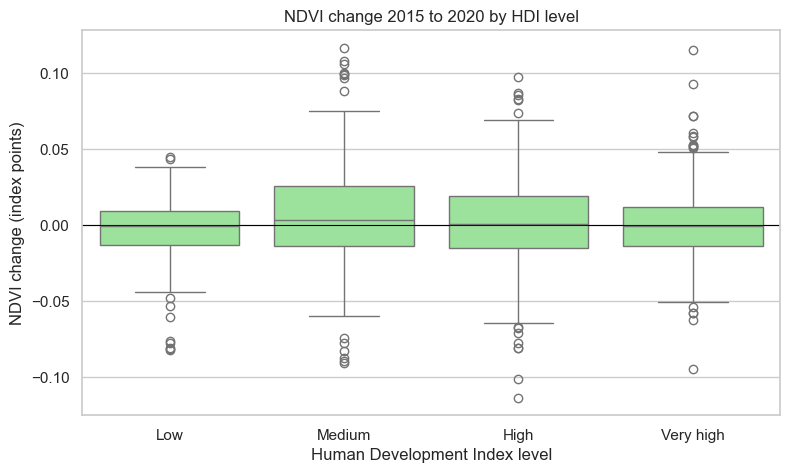

In [28]:
order = ["Low", "Medium", "High", "Very high"]

plt.figure()
sns.boxplot(data=analysis, x="HDI_level", y="NDVI_change_2015_2020", order=order, color="lightgreen")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("NDVI change 2015 to 2020 by HDI level")
plt.xlabel("Human Development Index level")
plt.ylabel("NDVI change (index points)")
plt.savefig("charts/7_ndvi_change_by_hdi.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** the boxes overlap heavily and all groups are centred close to zero. The spread inside each group is larger than the difference between groups, so HDI level is not a strong predictor of NDVI change.